# Week 3: Comparing Supervised Learning Models
**Fayz Liaqat | 23 October 2026**

I continue with my Week 2 loan dataset and compare KNN, a Decision Tree, and
Logistic Regression. The aim is to evaluate their predictions, understand
their mistakes, and explain which model I would choose for this exercise.

The opening goal also mentions Linear Regression, so I include it separately
as an extra comparison. The target is categorical, so the three classifiers
are the main models. Linear Regression is not a probability classifier.

**Dataset:** [Loan Predication on Kaggle](https://www.kaggle.com/datasets/ninzaami/loan-predication).
The included raw CSV has 614 data rows and 13 columns. No new download, API
key, or GPU is needed. Run this notebook from the project folder.

**Positive class:** 1 = historically approved. **Negative class:** 0 = historically not approved.
These labels do not tell us whether an applicant would repay a loan.

I use a fixed outer 80/20 split. A smaller validation split inside the
training set chooses the settings, so the final test set does not guide
tuning. One split gives limited evidence; these results are for coursework.

## Step 1: Prepare the data
I check the raw data, remove exact duplicate rows, and drop the application
ID from the inputs. I keep the Week 2 features `totalIncome` and
`hasCoapplicantIncome`. They describe combined income and whether there is
a positive co-applicant income contribution. They do not use the target.

Missing numbers will use training medians. Missing text will use the most
frequent training category. I leave the missing cells untouched until after
splitting, so no fill values are learned from the test set.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, mean_absolute_error,
    mean_squared_error, r2_score
)

projectDir = Path.cwd()
outputDir = projectDir / "outputs"
outputDir.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110

loanData = pd.read_csv(projectDir / "data" / "loan_data.csv")
print("Raw shape:", loanData.shape)
loanData.info()
display(loanData.head())
display(loanData.describe().T)
display(loanData.isna().sum().rename("missingCount").to_frame())
print("Exact duplicate rows:", loanData.duplicated().sum())
loanData = loanData.drop_duplicates().copy()

loanData = loanData.rename(columns={
    "Loan_ID": "loanId", "Gender": "gender", "Married": "married",
    "Dependents": "dependents", "Education": "education",
    "Self_Employed": "selfEmployed", "ApplicantIncome": "applicantIncome",
    "CoapplicantIncome": "coapplicantIncome", "LoanAmount": "loanAmount",
    "Loan_Amount_Term": "loanTerm", "Credit_History": "creditHistory",
    "Property_Area": "propertyArea", "Loan_Status": "loanStatus"
})
print("Missing targets:", loanData["loanStatus"].isna().sum())
loanData = loanData.dropna(subset=["loanStatus"]).copy()
assert loanData[["applicantIncome", "coapplicantIncome"]].notna().all().all()
loanData["totalIncome"] = loanData["applicantIncome"] + loanData["coapplicantIncome"]
loanData["hasCoapplicantIncome"] = (loanData["coapplicantIncome"] > 0).astype(int)

features = loanData.drop(columns=["loanId", "loanStatus"])
target = loanData["loanStatus"].map({"N": 0, "Y": 1})
assert target.notna().all()

Raw shape: (614, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.412162,85.587325,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.000000,65.120410,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.842199,0.364878,0.0,1.0,1.0,1.00,1.0


,missingCount
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


Exact duplicate rows: 0
Missing targets: 0


### Class balance
I count both target classes before training. Approved applications are more
common, so a model can get a reasonable-looking accuracy by always choosing
that class. Later I compare accuracy with per-class F1 and macro-F1.

,count,percent
loanStatus,,
0,192,31.27
1,422,68.73


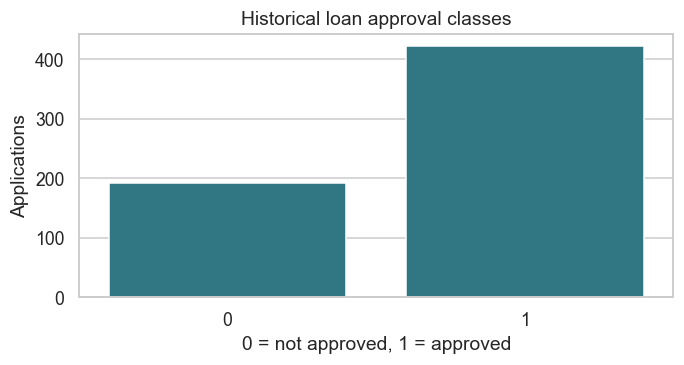

In [2]:
classBalance = pd.DataFrame({
    "count": target.value_counts().sort_index(),
    "percent": target.value_counts(normalize=True).sort_index().mul(100).round(2)
})
display(classBalance)
classBalance.to_csv(outputDir / "class_balance.csv", index_label="target")

plt.figure(figsize=(6.4, 3.5))
sns.countplot(x=target, order=[0, 1], color="#237F91")
plt.title("Historical loan approval classes")
plt.xlabel("0 = not approved, 1 = approved")
plt.ylabel("Applications")
plt.tight_layout()
plt.savefig(outputDir / "class_balance.png", dpi=180)
plt.show()
plt.close()

### Split before learning any preprocessing values
The outer split uses `test_size=0.20`, `stratify=target`, and
`random_state=42`: 491 training rows and 123 test rows.
I split only the 491 training rows again into 392 tuning rows and 99
validation rows. Validation accuracy chooses K and tree depth, as requested.
Validation macro-F1 chooses between the three model families because it
gives both classes equal weight. Ties favor higher approval precision,
then higher accuracy. A complete tie keeps the first listed model.

The test set stays untouched until the settings and chosen family are fixed.

In [3]:
trainInputs, testInputs, trainTarget, testTarget = train_test_split(
    features, target, test_size=0.20, random_state=42, stratify=target
)
tuningInputs, validationInputs, tuningTarget, validationTarget = train_test_split(
    trainInputs, trainTarget, test_size=0.20, random_state=42, stratify=trainTarget
)

splitSummary = pd.DataFrame({
    "rows": [len(tuningTarget), len(validationTarget), len(trainTarget), len(testTarget)],
    "approvedPercent": [
        tuningTarget.mean() * 100, validationTarget.mean() * 100,
        trainTarget.mean() * 100, testTarget.mean() * 100
    ]
}, index=["tuning", "validation", "full training", "test"])
display(splitSummary.round(2))

assert set(trainInputs.index).isdisjoint(testInputs.index)
assert set(tuningInputs.index).isdisjoint(validationInputs.index)

,rows,approvedPercent
tuning,392,68.62
validation,99,68.69
full training,491,68.64
test,123,69.11


### Impute, encode, and scale
I combine numeric and categorical pipelines with `ColumnTransformer`.
Numbers use median filling followed by `StandardScaler`; text uses mode
filling followed by `OneHotEncoder`. `dependents` stays categorical because
`3+` is a category. The binary `creditHistory` follows the numeric rule.

For tuning, `fit_transform` sees only the 392 tuning rows. Validation uses
only `transform`. After model selection, I create a fresh preprocessor and
fit it on all 491 training rows. The final test data receives only `transform`.
The one-hot columns remain 0/1, while numeric columns are standardized.

In [4]:
numericColumns = trainInputs.select_dtypes(include="number").columns.tolist()
categoricalColumns = trainInputs.select_dtypes(include="object").columns.tolist()

def makePreprocessor():
    numericPipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categoricalPipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("numeric", numericPipeline, numericColumns),
        ("categorical", categoricalPipeline, categoricalColumns)
    ])

tuningPreprocessor = makePreprocessor()
scaledTuningInputs = tuningPreprocessor.fit_transform(tuningInputs)
scaledValidationInputs = tuningPreprocessor.transform(validationInputs)
print("Numeric columns:", numericColumns)
print("Categorical columns:", categoricalColumns)
print("Tuning shape:", scaledTuningInputs.shape)
print("Validation shape:", scaledValidationInputs.shape)
assert np.isfinite(scaledTuningInputs).all()
assert np.isfinite(scaledValidationInputs).all()

Numeric columns: ['applicantIncome', 'coapplicantIncome', 'loanAmount', 'loanTerm', 'creditHistory', 'totalIncome', 'hasCoapplicantIncome']
Categorical columns: ['gender', 'married', 'dependents', 'education', 'selfEmployed', 'propertyArea']
Tuning shape: (392, 22)
Validation shape: (99, 22)


## Step 2: K-Nearest Neighbors
I first train the required `KNeighborsClassifier(n_neighbors=5)`.
Then I try odd K values from 1 to 15. The chart uses validation accuracy,
not test accuracy. I choose the highest validation accuracy; a tie keeps
the smaller K because the values are checked in ascending order.

K = 5 validation accuracy: 0.8181818181818182


,k,validationAccuracy
0,1,0.737374
1,3,0.747475
2,5,0.818182
3,7,0.808081
4,9,0.808081
5,11,0.808081
6,13,0.797980
7,15,0.797980


Chosen K: 5


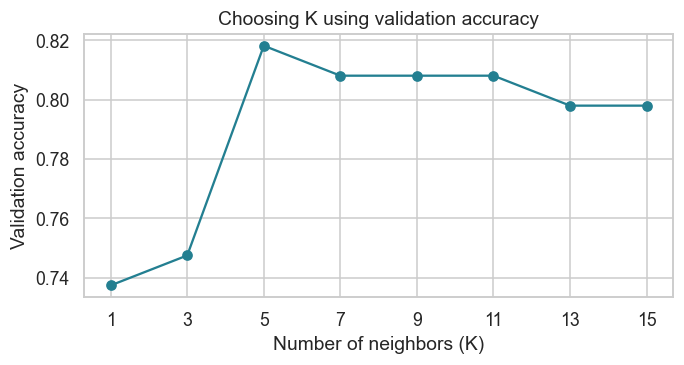

In [5]:
knnFive = KNeighborsClassifier(n_neighbors=5)
knnFive.fit(scaledTuningInputs, tuningTarget)
print("K = 5 validation accuracy:", accuracy_score(
    validationTarget, knnFive.predict(scaledValidationInputs)
))

knnResults = []
for kValue in range(1, 16, 2):
    knnCandidate = KNeighborsClassifier(n_neighbors=kValue)
    knnCandidate.fit(scaledTuningInputs, tuningTarget)
    knnResults.append({
        "k": kValue,
        "validationAccuracy": accuracy_score(
            validationTarget, knnCandidate.predict(scaledValidationInputs)
        )
    })
knnResults = pd.DataFrame(knnResults)
bestK = int(knnResults.loc[knnResults["validationAccuracy"].idxmax(), "k"])
display(knnResults)
print("Chosen K:", bestK)
knnResults.to_csv(outputDir / "knn_tuning.csv", index=False)

plt.figure(figsize=(6.4, 3.5))
plt.plot(knnResults["k"], knnResults["validationAccuracy"], marker="o", color="#237F91")
plt.xticks(list(range(1, 16, 2)))
plt.title("Choosing K using validation accuracy")
plt.xlabel("Number of neighbors (K)")
plt.ylabel("Validation accuracy")
plt.tight_layout()
plt.savefig(outputDir / "knn_accuracy.png", dpi=180)
plt.show()
plt.close()

## Step 3: Decision Tree
I compare depths 2, 3, 5, 10, and `None`. `None` allows the tree to grow
until its stopping rules are met. Each tree uses `random_state=42`.
I choose the highest validation accuracy; a tie keeps the shallower tree.

I also record training accuracy. A very deep tree can memorize training
examples. A large gap between training and validation accuracy suggests
overfitting, although one split does not prove how well it will generalize.

,maxDepth,actualDepth,trainingAccuracy,validationAccuracy
0,2,2,0.813776,0.787879
1,3,3,0.813776,0.787879
2,5,5,0.829082,0.787879
3,10,10,0.964286,0.747475
4,None,14,1.000000,0.757576


Chosen max_depth: 2


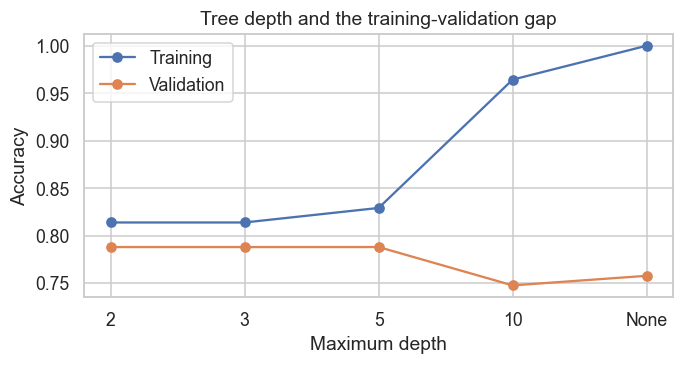

In [6]:
depthValues = [2, 3, 5, 10, None]
treeResults = []
for depthValue in depthValues:
    treeCandidate = DecisionTreeClassifier(max_depth=depthValue, random_state=42)
    treeCandidate.fit(scaledTuningInputs, tuningTarget)
    treeResults.append({
        "maxDepth": str(depthValue),
        "actualDepth": treeCandidate.get_depth(),
        "trainingAccuracy": accuracy_score(
            tuningTarget, treeCandidate.predict(scaledTuningInputs)
        ),
        "validationAccuracy": accuracy_score(
            validationTarget, treeCandidate.predict(scaledValidationInputs)
        )
    })
treeResults = pd.DataFrame(treeResults)
bestDepthIndex = treeResults["validationAccuracy"].idxmax()
bestDepth = depthValues[bestDepthIndex]
display(treeResults)
print("Chosen max_depth:", bestDepth)
treeResults.to_csv(outputDir / "tree_tuning.csv", index=False)

plt.figure(figsize=(6.4, 3.5))
plt.plot(treeResults["maxDepth"], treeResults["trainingAccuracy"], marker="o", label="Training")
plt.plot(treeResults["maxDepth"], treeResults["validationAccuracy"], marker="o", label="Validation")
plt.title("Tree depth and the training-validation gap")
plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(outputDir / "tree_depth_accuracy.png", dpi=180)
plt.show()
plt.close()

## Step 4: Logistic Regression and model selection
Logistic Regression is a classifier despite its name. It estimates the
probability of each class. I use `max_iter=1000` to give the solver enough
iterations. After validation selects the settings, I refit the models
on all training rows and print the required five test-row probabilities.

I compare the three tuned model families on validation data. Macro-F1
averages the two class F1-scores equally, so minority-class mistakes still
matter. Accuracy tunes K and depth; macro-F1 selects the model family.
The chosen family is fixed before looking at any test performance.

In [7]:
def calculateScores(modelName, actualTarget, predictedTarget):
    return {
        "Model": modelName,
        "Accuracy": accuracy_score(actualTarget, predictedTarget),
        "Precision": precision_score(actualTarget, predictedTarget, zero_division=0),
        "Recall": recall_score(actualTarget, predictedTarget, zero_division=0),
        "F1": f1_score(actualTarget, predictedTarget, zero_division=0),
        "Macro F1": f1_score(actualTarget, predictedTarget, average="macro", zero_division=0)
    }

candidateModels = {
    "KNN": KNeighborsClassifier(n_neighbors=bestK),
    "Decision Tree": DecisionTreeClassifier(max_depth=bestDepth, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}
validationResults = []
for modelName, candidateModel in candidateModels.items():
    candidateModel.fit(scaledTuningInputs, tuningTarget)
    validationPredictions = candidateModel.predict(scaledValidationInputs)
    validationResults.append(calculateScores(modelName, validationTarget, validationPredictions))
validationResults = pd.DataFrame(validationResults)
rankedValidation = validationResults.sort_values(
    ["Macro F1", "Precision", "Accuracy"], ascending=False, kind="stable"
)
bestModelName = rankedValidation.iloc[0]["Model"]
display(validationResults.round(4))
print("Model selected before test evaluation:", bestModelName)
validationResults.to_csv(outputDir / "validation_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1,Macro F1
0,KNN,0.8182,0.7976,0.9853,0.8816,0.7451
1,Decision Tree,0.7879,0.7765,0.9706,0.8627,0.6980
2,Logistic Regression,0.7879,0.7765,0.9706,0.8627,0.6980


Model selected before test evaluation: KNN


### Refit the fixed models on all training rows
The configurations and chosen family are now fixed. I refit a fresh
preprocessor on all 491 training rows, then transform the 123 test rows.
Each classifier is trained on the same processed training inputs and
used to predict the same test rows. I do not change settings afterward.

In [8]:
finalPreprocessor = makePreprocessor()
scaledTrainInputs = finalPreprocessor.fit_transform(trainInputs)
scaledTestInputs = finalPreprocessor.transform(testInputs)
print("Final training shape:", scaledTrainInputs.shape)
print("Final test shape:", scaledTestInputs.shape)

assert np.isfinite(scaledTrainInputs).all()
assert np.isfinite(scaledTestInputs).all()
assert scaledTrainInputs.shape[1] == scaledTestInputs.shape[1]
assert trainInputs.index.equals(trainTarget.index)
assert testInputs.index.equals(testTarget.index)

fittedNumeric = finalPreprocessor.named_transformers_["numeric"]
np.testing.assert_allclose(
    fittedNumeric.named_steps["imputer"].statistics_, trainInputs[numericColumns].median()
)
assert fittedNumeric.named_steps["scaler"].n_samples_seen_ == len(trainInputs)
assert trainInputs["creditHistory"].median() in [0, 1]
print("Zero missing/infinite input values. Preprocessor fitted on training rows only.")

finalModels = {}
testPredictions = {}
for modelName, candidateModel in candidateModels.items():
    finalModel = clone(candidateModel)
    finalModel.fit(scaledTrainInputs, trainTarget)
    finalModels[modelName] = finalModel
    testPredictions[modelName] = finalModel.predict(scaledTestInputs)

Final training shape: (491, 22)
Final test shape: (123, 22)
Zero missing/infinite input values. Preprocessor fitted on training rows only.


### Logistic Regression probabilities for five test rows
`predict_proba` returns one probability per class. I use `classes_` to
label the columns correctly. These are model estimates and have not
been checked for probability calibration.

In [9]:
logisticModel = finalModels["Logistic Regression"]
firstFiveProbabilities = logisticModel.predict_proba(scaledTestInputs[:5])
probabilityTable = pd.DataFrame(
    firstFiveProbabilities,
    columns=[f"probabilityClass{classValue}" for classValue in logisticModel.classes_],
    index=testInputs.index[:5]
)
probabilityTable["actualClass"] = testTarget.iloc[:5]
probabilityTable["predictedClass"] = testPredictions["Logistic Regression"][:5]
display(probabilityTable.round(4))
probabilityTable.to_csv(outputDir / "logistic_probabilities.csv", index_label="sourceRow")
assert np.allclose(firstFiveProbabilities.sum(axis=1), 1)

,probabilityClass0,probabilityClass1,actualClass,predictedClass
150,0.9594,0.0406,0,0
559,0.0787,0.9213,1,1
598,0.3189,0.6811,1,1
235,0.2384,0.7616,1,1
145,0.0987,0.9013,1,1


## Step 5: Evaluate all three classifiers
I evaluate the fixed classifiers on the held-out test set using accuracy,
a confusion matrix, and the full classification report.

Precision, recall, and F1 in the comparison table use **approved (1)**
as the positive class. The classification reports also show the rejected
class separately, and macro-F1 gives both classes equal weight.
In every confusion matrix, rows are actual labels and columns are predictions.

KNN
              precision    recall  f1-score   support

Not approved     0.9259    0.6579    0.7692        38
    Approved     0.8646    0.9765    0.9171        85

    accuracy                         0.8780       123
   macro avg     0.8953    0.8172    0.8432       123
weighted avg     0.8835    0.8780    0.8714       123

Decision Tree
              precision    recall  f1-score   support

Not approved     0.8800    0.5789    0.6984        38
    Approved     0.8367    0.9647    0.8962        85

    accuracy                         0.8455       123
   macro avg     0.8584    0.7718    0.7973       123
weighted avg     0.8501    0.8455    0.8351       123



Logistic Regression
              precision    recall  f1-score   support

Not approved     0.9565    0.5789    0.7213        38
    Approved     0.8400    0.9882    0.9081        85

    accuracy                         0.8618       123
   macro avg     0.8983    0.7836    0.8147       123
weighted avg     0.8760    0.8618    0.8504       123



,Model,Accuracy,Precision,Recall,F1,Macro F1
0,KNN,0.8780,0.8646,0.9765,0.9171,0.8432
1,Decision Tree,0.8455,0.8367,0.9647,0.8962,0.7973
2,Logistic Regression,0.8618,0.8400,0.9882,0.9081,0.8147


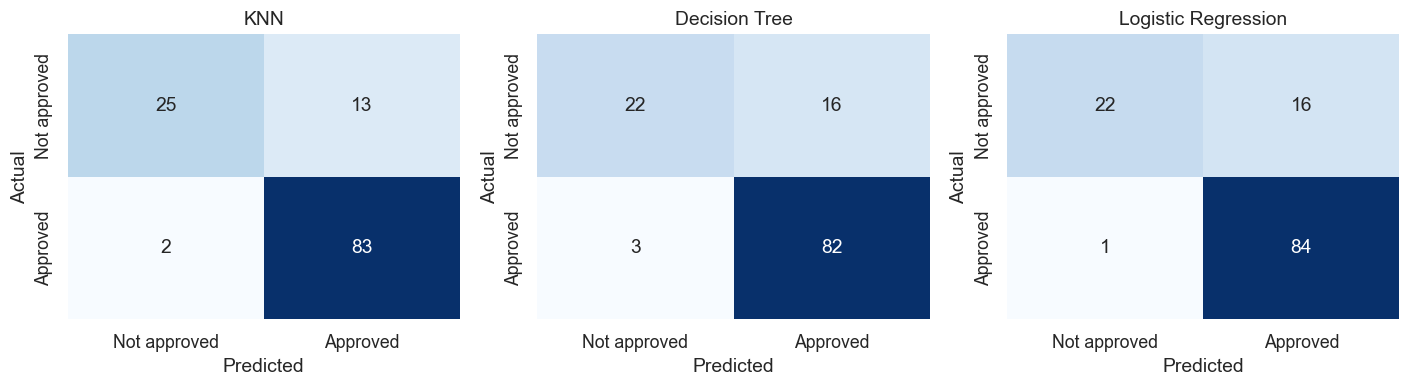

In [10]:
modelResults = []
for modelName, predictions in testPredictions.items():
    modelResults.append(calculateScores(modelName, testTarget, predictions))

    reportText = classification_report(
        testTarget, predictions, labels=[0, 1],
        target_names=["Not approved", "Approved"], digits=4, zero_division=0
    )
    print(modelName)
    print(reportText)
    reportFileName = modelName.lower().replace(" ", "_") + "_classification_report.txt"
    (outputDir / reportFileName).write_text(reportText, encoding="utf-8")

comparisonTable = pd.DataFrame(modelResults)
display(comparisonTable.round(4))
comparisonTable.to_csv(outputDir / "model_comparison.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
for axis, modelName in zip(axes, finalModels):
    modelMatrix = confusion_matrix(testTarget, testPredictions[modelName], labels=[0, 1])
    sns.heatmap(modelMatrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Not approved", "Approved"],
                yticklabels=["Not approved", "Approved"], ax=axis)
    axis.set_title(modelName)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(outputDir / "confusion_matrices.png", dpi=180)
plt.show()
plt.close()

## Step 6: Understand the selected model's mistakes
I inspect the model selected by validation macro-F1, rather than choosing
a new winner after seeing test scores. A false positive here means
predicting approval for a historically rejected application. A false
negative means predicting rejection for a historically approved application.

For a hypothetical approval-screening use case, I would treat false
positives as more costly and prioritize approval precision, while also
monitoring rejection errors and both class F1-scores. This is a stated
assumption, not a measured financial cost. Historical rejection does not
prove default or poor creditworthiness. The exercise cannot establish
lending safety or fairness.

Selected model: KNN
Correctly predicted not approved: 25
False approvals: 13
False rejections: 2
Correctly predicted approved: 83


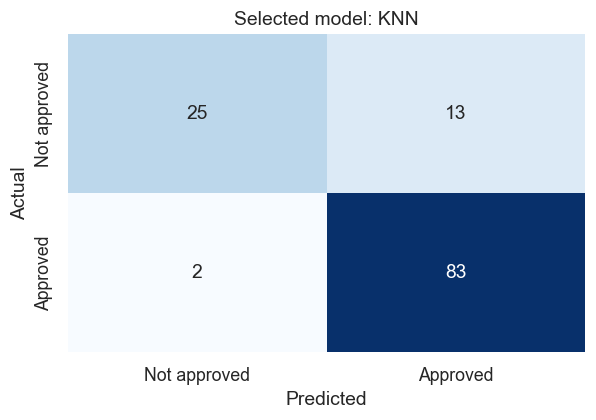

,loanId,gender,married,dependents,education,selfEmployed,applicantIncome,coapplicantIncome,loanAmount,loanTerm,creditHistory,propertyArea,totalIncome,hasCoapplicantIncome,actualClass,predictedClass
326,LP002068,Male,No,0,Graduate,No,4917,0.0,130.0,360.0,0.0,Rural,4917.0,0,1,0
268,LP001883,Female,No,0,Graduate,NaN,3418,0.0,135.0,360.0,1.0,Rural,3418.0,0,0,1
479,LP002533,Male,Yes,2,Graduate,No,2947,1603.0,NaN,360.0,1.0,Urban,4550.0,1,0,1
216,LP001722,Male,Yes,0,Graduate,No,150,1800.0,135.0,360.0,1.0,Rural,1950.0,1,0,1
487,LP002547,Male,Yes,1,Graduate,No,18333,0.0,500.0,360.0,1.0,Urban,18333.0,0,0,1
510,LP002637,Male,No,0,Not Graduate,No,3598,1287.0,100.0,360.0,1.0,Rural,4885.0,1,0,1
153,LP001532,Male,Yes,2,Not Graduate,No,2281,0.0,113.0,360.0,1.0,Rural,2281.0,0,0,1
190,LP001653,Male,No,0,Not Graduate,No,4885,0.0,48.0,360.0,1.0,Rural,4885.0,0,1,0
314,LP002024,NaN,Yes,0,Graduate,No,2473,1843.0,159.0,360.0,1.0,Rural,4316.0,1,0,1
426,LP002367,Female,No,1,Not Graduate,No,4606,0.0,81.0,360.0,1.0,Rural,4606.0,0,0,1


Mistakes by actual class:


actualClass
0    13
1     2
Name: count, dtype: int64

In [11]:
bestPredictions = testPredictions[bestModelName]
bestMatrix = confusion_matrix(testTarget, bestPredictions, labels=[0, 1])
trueNegative, falsePositive, falseNegative, truePositive = bestMatrix.ravel()
print("Selected model:", bestModelName)
print("Correctly predicted not approved:", trueNegative)
print("False approvals:", falsePositive)
print("False rejections:", falseNegative)
print("Correctly predicted approved:", truePositive)

plt.figure(figsize=(5.6, 4))
sns.heatmap(bestMatrix, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Not approved", "Approved"],
            yticklabels=["Not approved", "Approved"])
plt.title(f"Selected model: {bestModelName}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(outputDir / "best_model_confusion_matrix.png", dpi=180)
plt.show()
plt.close()

errorDetails = testInputs.copy()
errorDetails.insert(0, "loanId", loanData.loc[testInputs.index, "loanId"])
errorDetails["actualClass"] = testTarget
errorDetails["predictedClass"] = bestPredictions
errorDetails = errorDetails[errorDetails["actualClass"] != errorDetails["predictedClass"]]
display(errorDetails.head(10))
print("Mistakes by actual class:")
display(errorDetails["actualClass"].value_counts().sort_index())
errorDetails.to_csv(outputDir / "best_model_errors.csv", index_label="sourceRow")

## Bonus: Is accuracy alone misleading?
I train a majority-class dummy model on the training targets. It always
predicts the most common training class, without learning useful input
patterns. I compare it with the three classifiers using accuracy,
approval F1, rejection F1, and macro-F1.

Approval F1 can also look good when approval is the majority class.
The rejection F1 and macro-F1 make the weaker class easier to see.

In [12]:
dummyModel = DummyClassifier(strategy="most_frequent")
dummyModel.fit(scaledTrainInputs, trainTarget)
dummyPredictions = dummyModel.predict(scaledTestInputs)
imbalanceResults = []
for modelName, predictions in {**testPredictions, "Majority baseline": dummyPredictions}.items():
    imbalanceResults.append({
        "Model": modelName,
        "Accuracy": accuracy_score(testTarget, predictions),
        "Approved F1": f1_score(testTarget, predictions, pos_label=1, zero_division=0),
        "Not approved F1": f1_score(testTarget, predictions, pos_label=0, zero_division=0),
        "Macro F1": f1_score(testTarget, predictions, average="macro", zero_division=0)
    })
imbalanceResults = pd.DataFrame(imbalanceResults)
display(imbalanceResults.round(4))
imbalanceResults.to_csv(outputDir / "accuracy_vs_f1.csv", index=False)

,Model,Accuracy,Approved F1,Not approved F1,Macro F1
0,KNN,0.8780,0.9171,0.7692,0.8432
1,Decision Tree,0.8455,0.8962,0.6984,0.7973
2,Logistic Regression,0.8618,0.9081,0.7213,0.8147
3,Majority baseline,0.6911,0.8173,0.0000,0.4087


## Extra: Linear Regression from the opening goal
Linear Regression fits a continuous number, so accuracy and a confusion
matrix cannot be calculated directly on its raw scores. I train it on
the same 0/1 target as a demonstration, and convert scores to classes
with a **fixed threshold of 0.5**. That threshold is not tuned on test data.

I show the thresholded classification metrics and also MAE, RMSE, and
R-squared for the raw scores. Raw scores can fall outside 0 to 1 and
must not be described as probabilities. This extra model is separate
from the three-classifier selection required by the detailed steps.

,Model,Accuracy,Precision,Recall,F1,Macro F1
0,Linear Regression (threshold 0.5),0.8618,0.84,0.9882,0.9081,0.8147


,MAE,RMSE,R2,minimumScore,maximumScore
0,0.2575,0.3413,0.4543,-0.0616,1.018


              precision    recall  f1-score   support

Not approved     0.9565    0.5789    0.7213        38
    Approved     0.8400    0.9882    0.9081        85

    accuracy                         0.8618       123
   macro avg     0.8983    0.7836    0.8147       123
weighted avg     0.8760    0.8618    0.8504       123



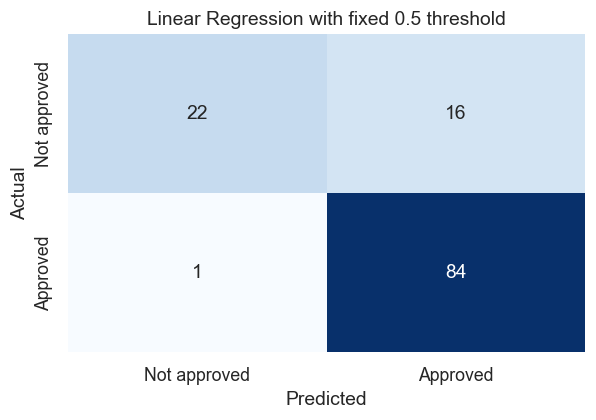

In [13]:
linearModel = LinearRegression()
linearModel.fit(scaledTrainInputs, trainTarget)
linearScores = linearModel.predict(scaledTestInputs)
linearPredictions = (linearScores >= 0.5).astype(int)

linearClassification = pd.DataFrame([
    calculateScores("Linear Regression (threshold 0.5)", testTarget, linearPredictions)
])
linearRegressionMetrics = pd.DataFrame([{
    "MAE": mean_absolute_error(testTarget, linearScores),
    "RMSE": np.sqrt(mean_squared_error(testTarget, linearScores)),
    "R2": r2_score(testTarget, linearScores),
    "minimumScore": linearScores.min(),
    "maximumScore": linearScores.max()
}])
display(linearClassification.round(4))
display(linearRegressionMetrics.round(4))
print(classification_report(testTarget, linearPredictions, labels=[0, 1],
                            target_names=["Not approved", "Approved"], digits=4, zero_division=0))
linearClassification.to_csv(outputDir / "linear_classification.csv", index=False)
linearRegressionMetrics.to_csv(outputDir / "linear_regression_metrics.csv", index=False)

plt.figure(figsize=(5.6, 4))
sns.heatmap(confusion_matrix(testTarget, linearPredictions, labels=[0, 1]),
            annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Not approved", "Approved"], yticklabels=["Not approved", "Approved"])
plt.title("Linear Regression with fixed 0.5 threshold")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(outputDir / "linear_confusion_matrix.png", dpi=180)
plt.show()
plt.close()

### Save predictions for checking the results
I keep the actual and predicted labels in the same test-row order.
The application ID is included only for reviewing errors; no model
receives it as an input. The saved files make the reported scores easy
to check without guessing or copying values by hand.

In [14]:
predictionTable = pd.DataFrame({"actualClass": testTarget})
for modelName, predictions in testPredictions.items():
    predictionTable[modelName] = predictions
predictionTable["Majority baseline"] = dummyPredictions
predictionTable["Linear Regression"] = linearPredictions
predictionTable["linearScore"] = linearScores
predictionTable.to_csv(outputDir / "test_predictions.csv", index_label="sourceRow")
print("Saved model comparisons, tuning tables, probabilities, errors, and predictions.")
print("The test results were not used to change K, tree depth, or the chosen model family.")

Saved model comparisons, tuning tables, probabilities, errors, and predictions.
The test results were not used to change K, tree depth, or the chosen model family.


## Results explained in my own words

**My selected classifier is KNN.** It had the highest validation
macro-F1 (0.7451), so I chose
it before evaluating the test data. It then reached **87.80% test accuracy**,
**0.9171 approval F1**, and **0.8432 macro-F1**.
It also has the highest accuracy, approval precision, and macro-F1 among the
three classifiers on this test split. Logistic Regression has slightly higher
approval recall, so the models have different tradeoffs. This is evidence from
one small split, not proof that KNN is always better.

**K and tree depth:** K = 5 gave 81.82%
validation accuracy, the best value among the odd numbers 1 to 15.
Depth 2 gave 78.79%; depths 3 and 5 tied it,
so I kept the simpler depth-2 tree. The unlimited tree reached
100.00% training accuracy but only
75.76% validation accuracy, which suggests overfitting.

**Where KNN makes mistakes:** It correctly rejected 25 applications and
correctly approved 83. It made 13 false approvals and 2 false
rejections, for 15 errors in total. It found only 25 of the
38 historically rejected applications, a rejection recall of
65.79%. Its strong approval recall therefore hides a weaker
result on the rejected class. All 13 false-approval examples in the saved error
file have recorded creditHistory = 1. This is an observation about those rows,
not evidence that this feature caused the predictions.

**Which metric matters:** Under my stated assumption that false approvals
are more costly, approval precision matters most. KNN's precision is
86.46%: 83 of its 96 predicted approvals match the
historical label. I still check recall and both class F1-scores. These data do
not contain repayment outcomes, so I cannot convert those errors into default
risk, financial loss, or a claim that the historical labels are fair.

**Why accuracy alone is misleading:** The majority baseline gets
69.11% accuracy and 0.8173 approval F1 while never
recognizing the rejected class. Its rejection F1 is 0.0000 and macro-F1
is only 0.4087. KNN's rejection F1 is
0.7692. Looking at both classes gives
a more useful picture than reporting accuracy or majority-class F1 alone.

**Linear Regression:** With the predeclared 0.5 threshold, it gets
86.18% accuracy and 0.9081 approval F1. Its predicted
classes match Logistic Regression on this particular test set, but the models
are different. Its raw scores range from -0.0616 to
1.0180, so treating them as probabilities would be incorrect.

## What I learned and the limits of this experiment
I learned that fitting a scaler correctly is only part of avoiding
leakage. Choosing K or depth from test scores also uses the test set
for training decisions. Keeping a validation split made that separation
clearer. It leaves fewer fitting rows, so this small dataset has noisy
estimates. Cross-validation would be a reasonable later improvement.

The other challenge was interpreting Linear Regression in a classification
assignment. A fixed threshold makes a comparison possible, but its raw
scores remain continuous values, not calibrated probabilities.

I checked both classes rather than using accuracy alone. The models
learn historical approval patterns, not repayment outcomes. There is
no external validation, fairness assessment, or evidence of lending readiness.

**Sources:** [Dataset](https://www.kaggle.com/datasets/ninzaami/loan-predication),
[scikit-learn model evaluation](https://scikit-learn.org/1.8/modules/model_evaluation.html),
[LinearRegression documentation](https://scikit-learn.org/1.8/modules/generated/sklearn.linear_model.LinearRegression.html).